# Regression from images — train and evaluate

Training is one call; the interesting part is *reading what comes out*. This notebook trains, plots the learning curves, evaluates on the test split, and shows you how to interpret each number.

In [1]:
# Run this cell first.
# On Colab it clones the kit and installs what's missing; locally it just finds the repo root.
import os, sys, subprocess
from pathlib import Path

if "google.colab" in sys.modules and not Path("cvkit").exists():
    subprocess.run(["git", "clone", "-q", "https://github.com/standungan/computer-vision-starter-kit"], check=True)
    os.chdir("computer-vision-starter-kit")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pyyaml", "scikit-learn", "gradio"], check=True)
while not Path("cvkit").exists() and Path.cwd() != Path.cwd().parent:
    os.chdir(Path.cwd().parent)          # notebooks live 3 folders below the repo root
sys.path.insert(0, os.getcwd())
print("working in", Path.cwd().name)

working in computer-vision-starter-kit


In [2]:
%config InlineBackend.figure_format = "jpeg"
%config InlineBackend.print_figure_kwargs = {"bbox_inches": "tight", "pil_kwargs": {"quality": 90}}   # keeps saved notebooks small

from PIL import Image

from cvkit.config import load_config
from cvkit.synthetic import make_demo_data
from cvkit.utils import seed_everything

# quick.yaml = small synthetic demo, runs on a laptop CPU in minutes.
# Swap in default.yaml (bigger, pretrained) or your own config + data when you're ready.
CONFIG = "tasks/regression/configs/quick.yaml"
cfg = load_config(CONFIG)
seed_everything(cfg["seed"])

if not Path(cfg["data"]["root"]).exists():          # first run: create the demo dataset
    make_demo_data("regression", cfg)
print("task:", "regression", "| data:", cfg["data"]["root"], "| outputs:", cfg["output"]["dir"])

task: regression | data: data/demo/regression | outputs: outputs/regression_quick


## The configuration
Everything tunable is in one YAML file. These are the sections that matter:

In [3]:
import yaml

for section in ('data', 'model', 'train'):
    print(section + ':')
    for line in yaml.safe_dump(cfg[section], sort_keys=False).splitlines():
        print('  ' + line)

data:
  root: data/demo/regression
  images_dir: images
  labels_file: labels.csv
  image_size: 96
  batch_size: 16
  num_workers: 0
  split:
    train: 0.7
    val: 0.15
    test: 0.15
  augment:
    hflip: true
    vflip: true
    rotation: 0
    color_jitter: 0.0
    random_erasing: 0.0
model:
  arch: resnet18
  pretrained: false
  freeze_backbone: false
  dropout: 0.0
train:
  epochs: 20
  lr: 0.002
  weight_decay: 0.0001
  loss: huber
  amp: true
  early_stopping_patience: 0


## What are we about to train?

In [4]:
from cvkit.utils import count_parameters
from tasks.regression.data import build_loaders
from tasks.regression.model import build_model

stats = build_loaders(cfg)["stats"]
model = build_model(cfg, {})
p = count_parameters(model)
print(f"arch {cfg['model']['arch']} | pretrained {cfg['model']['pretrained']} | loss: {cfg['train']['loss']}")
print(f"{p['total']:,} parameters, {p['trainable']:,} trainable | target '{stats['target_name']}': mean {stats['mean']:.2f}, std {stats['std']:.2f}")
del model

arch resnet18 | pretrained False | loss: huber
11,177,025 parameters, 11,177,025 trainable | target 'value': mean 21.69, std 7.97


## Train
Watch the `val` numbers: they are what picks the best epoch.

In [5]:
from tasks.regression.train import train

result = train(cfg)
print('\nbest epoch:', result['best_epoch'], '|', {k: round(v, 4) for k, v in result['best_metrics'].items()})

arch: resnet18 | target 'value': train mean 21.691, std 7.969
device: cpu | parameters: 11,177,025 total, 11,177,025 trainable (100.0%)


epoch   1/20 | train_loss 0.8155 | val mae=14.041 rmse=15.317 r2=-2.650 | 2.8s  <- best


epoch   2/20 | train_loss 0.1592 | val mae=3.817 rmse=5.316 r2=0.560 | 2.8s  <- best


epoch   3/20 | train_loss 0.0763 | val mae=2.131 rmse=2.624 r2=0.893 | 2.8s  <- best


epoch   4/20 | train_loss 0.0539 | val mae=1.042 rmse=1.302 r2=0.974 | 2.9s  <- best


...

epoch  16/20 | train_loss 0.0088 | val mae=0.397 rmse=0.515 r2=0.996 | 3.0s  <- best


epoch  17/20 | train_loss 0.0037 | val mae=0.314 rmse=0.417 r2=0.997 | 3.0s  <- best


epoch  18/20 | train_loss 0.0061 | val mae=0.318 rmse=0.400 r2=0.998 | 2.9s


epoch  19/20 | train_loss 0.0033 | val mae=0.350 rmse=0.435 r2=0.997 | 2.9s


epoch  20/20 | train_loss 0.0040 | val mae=0.307 rmse=0.385 r2=0.998 | 3.1s  <- best
best val mae = 0.3067 (epoch 20) -> outputs/regression_quick/checkpoints/best.pt

best epoch: 20 | {'mae': 0.3067, 'rmse': 0.3846, 'r2': 0.9977}


## Learning curves
**Gap widening** between train and val → overfitting (more augmentation, fewer epochs, smaller model). **Both flat and poor** → underfitting (train longer, raise the learning rate, unfreeze the backbone). **Val bouncing hard** → learning rate too high, or the val split is small. Remember the quick preset trains for only a few epochs, so expect curves still on their way up. Here **mae** is the average miss in your units (lower is better).

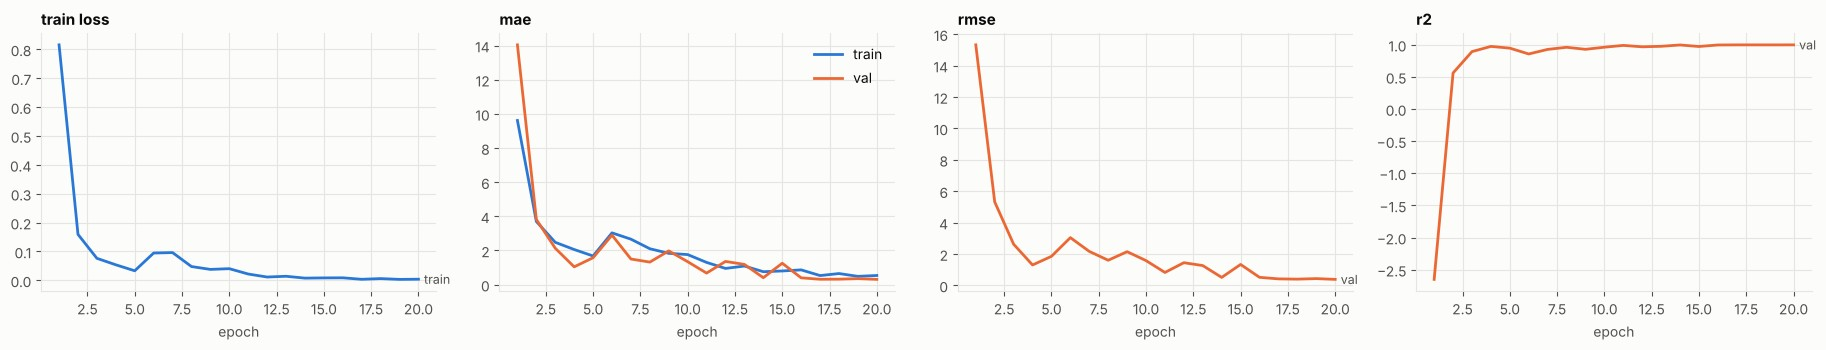

In [6]:
from cvkit.viz import plot_history

_ = plot_history(Path(cfg['output']['dir']) / 'history.csv')

## Evaluate on the test split
Val chose the checkpoint; the **test split** was untouched until now, so it is the honest number. One rule: look at test results, *don't tune on them* — the moment you tweak settings to chase the test score, it stops measuring generalisation.

In [7]:
from tasks.regression.evaluate import evaluate

metrics = evaluate(cfg)

value: MAE 0.406 | RMSE 0.533 | R2 0.996 (68 images)
for reference, always guessing the train mean would give MAE 7.565
reports -> outputs/regression_quick/reports


pred_vs_true.png


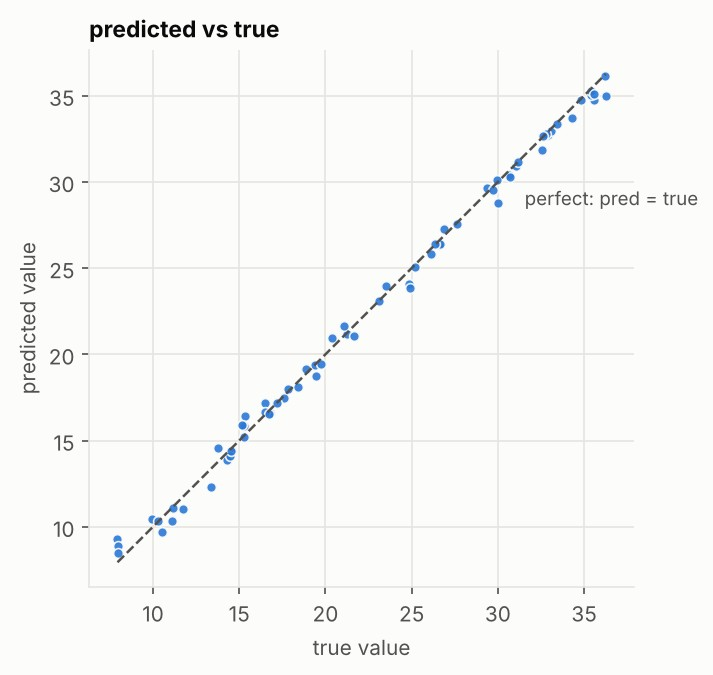

residuals.png


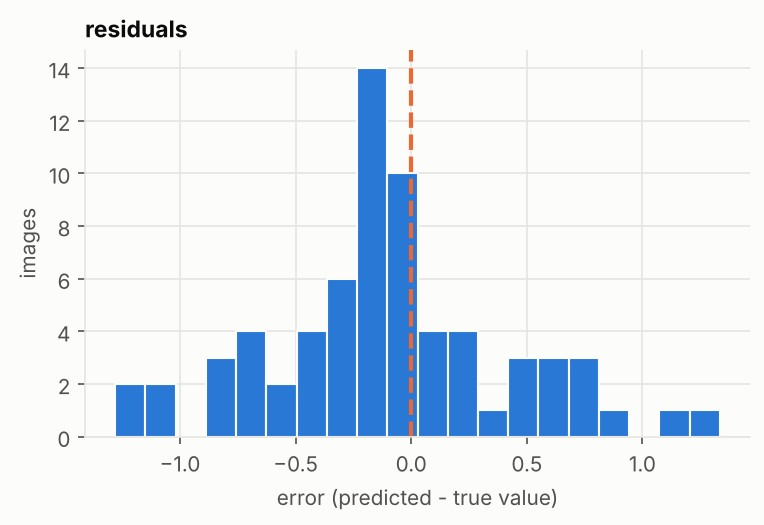

worst_errors.png


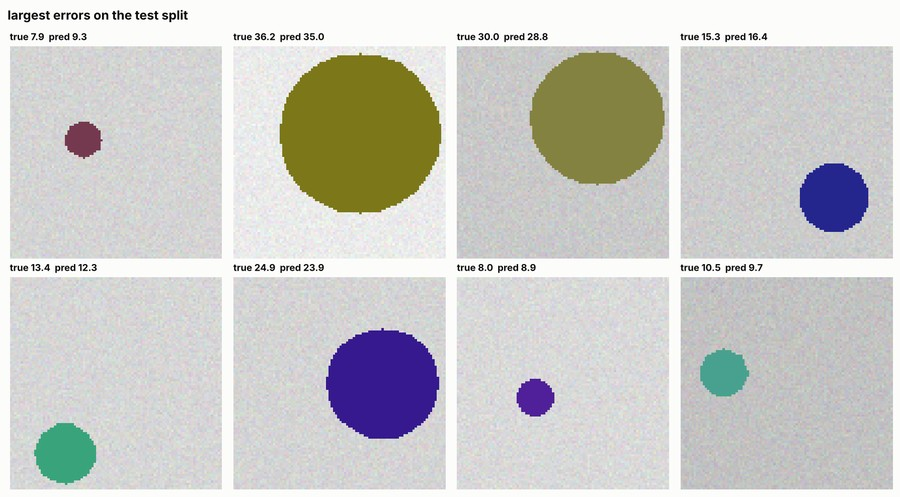

In [8]:
from cvkit.viz import show_image

reports = Path(cfg["output"]["dir"]) / "reports"
for name in ['pred_vs_true.png', 'residuals.png', 'worst_errors.png']:
    print(name)
    show_image(reports / name)

## How to read these results
* **MAE** — on average the prediction is this far off, in your target's units. The most interpretable number; compare it to the *baseline MAE* printed above.
* **RMSE** — like MAE but squares errors first, so a few big misses weigh more. RMSE much larger than MAE means a heavy tail of bad predictions.
* **R²** — 1 is perfect; 0 means no better than always predicting the mean; negative means worse than that.
* **Predicted vs true** — dots fanning out at the ends means the model is poor at extremes; a slope flatter than the diagonal means it squeezes predictions toward the mean.
* **Residuals** — centred on zero? Narrow? Skewed? A shifted centre is a bias you can sometimes fix.
* **Worst errors** — are these mislabelled, unusual images, or edge-of-range values?

## Experiments worth running
Each one is a one-line change. Re-run the training cell with a different config and compare the best val numbers (change `cfg` like this, then re-run from *Train*):

```python
cfg['model']['arch'] = 'resnet34'     # or any key, same as --set model.arch=resnet34
```

1. `train.loss = 'mse'` or `'l1'` instead of `'huber'` — how do outliers change things?
2. `model.arch = 'resnet34'`, then `'mobilenet_v3_small'`
3. `train.epochs` ×2 — is val MAE still falling?
4. Add noise to a few labels in `labels.csv` and see which loss copes best

Change **one thing at a time**, keep the seed, and write down what you changed — otherwise you can't tell what helped.

Next: **[03_predict_and_deploy](03_predict_and_deploy.ipynb)**.